In [1]:
import matplotlib.pyplot as plt
import pandas as pd
df = pd.read_csv(r"data_nettoyees.csv")

print("___COLONNES___")
print(df.columns.to_list())
print("\n---APERCU---")
print(df.head())


___COLONNES___
['date', 'ligne', 'taux_de_ponctualite', 'annee', 'mois', 'trimestre']

---APERCU---
         date ligne  taux_de_ponctualite  annee  mois  trimestre
0  2013-01-01     H                 93.9   2013     1          1
1  2013-01-01     J                 82.5   2013     1          1
2  2013-01-01     K                 75.2   2013     1          1
3  2013-01-01     L                 84.0   2013     1          1
4  2013-01-01     N                 94.7   2013     1          1


In [13]:

# Vérification rapide des valeurs manquantes et des bornes
print("Valeurs manquantes :\n", df.isna().sum())
print("\nPériode :", df["date"].min(), "à", df["date"].max())
print("Lignes :", df["ligne"].unique())

# Axe 1 : Classement et régularité par ligne
stats_lignes = (
    df.groupby("ligne")["taux_de_ponctualite"]
    .agg(
        nb_mois="count",
        moyenne="mean",
        mediane="median",
        minimum="min",
        maximum="max",
        ecart_type="std",
    )
    .sort_values(by="moyenne", ascending=False)
)

print("\n--- STATISTIQUES PAR LIGNE ---")
print(stats_lignes.round(2))
difference = stats_lignes["moyenne"].max() - stats_lignes["moyenne"].min()

print("écart entre la ligne la plus ponctuelle et la moins ponctuelle:", difference)

Valeurs manquantes :
 date                   0
ligne                  0
taux_de_ponctualite    0
annee                  0
mois                   0
trimestre              0
conforme_90            0
dtype: int64

Période : 2013-01-01 à 2026-10-01
Lignes : <StringArray>
['H', 'J', 'K', 'L', 'N', 'P', 'R', 'U']
Length: 8, dtype: str

--- STATISTIQUES PAR LIGNE ---
       nb_mois  moyenne  mediane  minimum  maximum  ecart_type
ligne                                                         
H          162    94.14    94.72    58.10    98.00        3.70
U          156    93.16    94.05    44.92    99.41        5.49
N          162    92.84    93.80    79.00    97.68        3.40
K          162    91.24    92.73    71.90    98.71        5.36
L          162    90.82    91.84    77.80    98.36        4.78
J          162    90.56    91.42    80.70    96.66        3.55
P          162    89.99    90.40    76.30    96.15        3.14
R          162    87.71    88.59    73.20    95.91        3.77
écart e

In [5]:
# Axe 2 : Évolution moyenne par année et par ligne
evo_annuelle = df.pivot_table(
    index="annee", columns="ligne", values="taux_de_ponctualite", aggfunc="mean"
)
print("\n--- ÉVOLUTION ANNUELLE ---")
print(evo_annuelle.round(2))

# Axe 3 : Saisonnalité (moyenne par mois sur l'ensemble du réseau et par ligne)
saisonnalite = df.pivot_table(
    index="mois", columns="ligne", values="taux_de_ponctualite", aggfunc="mean"
)
print("\n--- SAISONNALITÉ (PAR MOIS) ---")
print(saisonnalite.round(2))

# Axe 4 : Part de mois où la ponctualité atteint au moins 90 %
df["conforme_90"] = df["taux_de_ponctualite"] >= 90
taux_conformite = (
    df.groupby("ligne")["conforme_90"].mean() * 100
).sort_values(ascending=False)
print("\n--- % DE MOIS >= 90 % DE PONCTUALITÉ ---")
print(taux_conformite.round(1))


--- ÉVOLUTION ANNUELLE ---
ligne      H      J      K      L      N      P      R      U
annee                                                        
2013   94.22  85.68  80.36  84.17  92.72  89.00  89.05  92.08
2014   95.20  85.56  86.09  85.03  94.12  90.09  87.75  93.52
2015   94.83  88.21  87.83  83.42  92.20  90.38  87.62  93.30
2016   91.77  89.55  89.58  88.59  90.92  89.20  86.73  94.10
2017   90.98  90.24  92.52  88.41  89.70  90.30  83.39  92.96
2018   92.95  90.09  90.42  90.82  87.68  88.17  83.72  91.40
2019   94.09  90.42  92.49  93.10  92.17  87.95  85.84  95.14
2020   93.60  91.18  90.75  94.32  93.37  91.39  88.18  96.52
2021   95.47  93.09  93.40  94.73  93.67  91.68  88.27  95.82
2022   95.31  92.89  95.84  93.82  95.60  89.39  90.19  76.40
2023   94.89  92.75  94.51  94.25  93.92  89.22  89.38  95.11
2024   95.48  93.78  95.97  94.74  94.98  91.71  91.42  94.96
2025   94.85  93.65  94.01  94.19  95.25  91.44  89.10  93.02
2026   94.21  90.93  94.11  93.34  93.72  

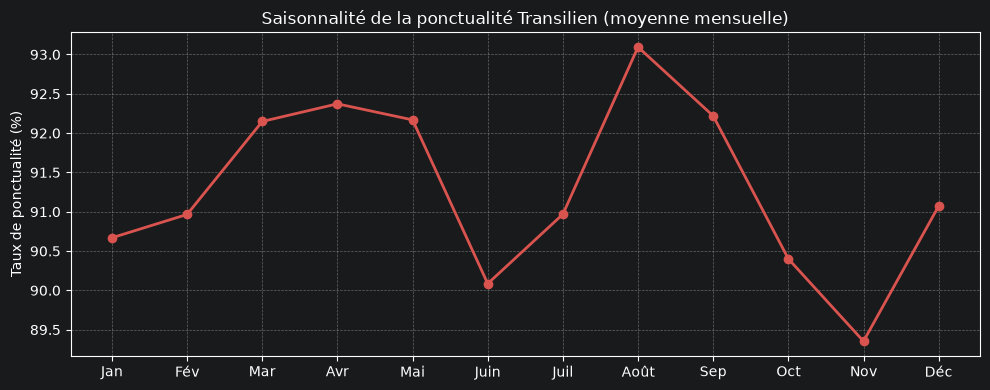

In [6]:
# Graphique 3 : Saisonnalité moyenne du réseau (toutes lignes confondues)
saison_reseau = df.groupby("mois")["taux_de_ponctualite"].mean()

plt.figure(figsize=(10, 4))
plt.plot(saison_reseau.index, saison_reseau.values, marker="o", color="#d9534f", linewidth=2)
plt.xticks(range(1, 13), ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"])
plt.title("Saisonnalité de la ponctualité Transilien (moyenne mensuelle)")
plt.ylabel("Taux de ponctualité (%)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("graph/3_saisonnalite.png", dpi=300)
plt.show()

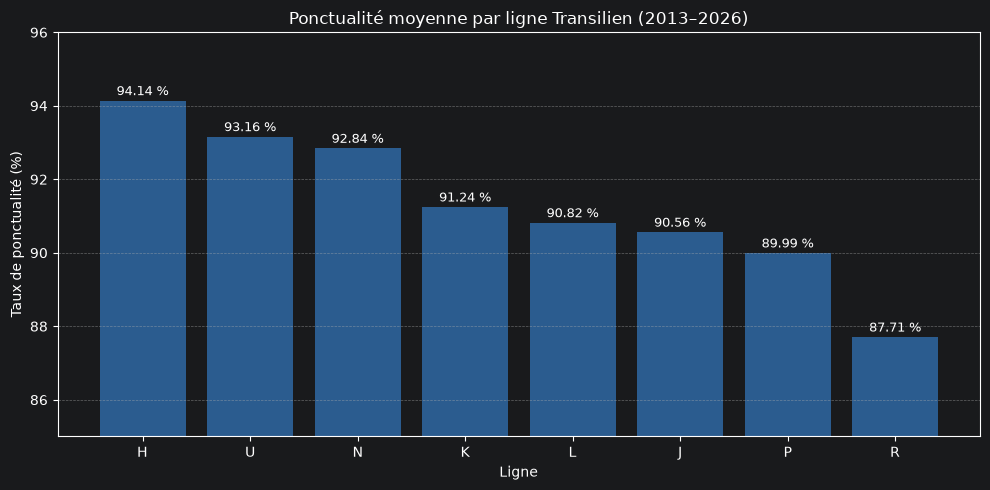

In [7]:
plt.figure(figsize=(10, 5))
bars = plt.bar(
    stats_lignes.index, stats_lignes["moyenne"], color="#2b5c8f"
)

plt.ylim(85, 96)
plt.title("Ponctualité moyenne par ligne Transilien (2013–2026)")
plt.ylabel("Taux de ponctualité (%)")
plt.xlabel("Ligne")
plt.grid(axis="y", linestyle="--", alpha=0.5)

# Afficher le pourcentage au-dessus de chaque barre
for bar in bars:
  yval = bar.get_height()
  plt.text(
      bar.get_x() + bar.get_width() / 2,
      yval + 0.15,
      f"{yval:.2f} %",
      ha="center",
      fontsize=9,
  )

plt.tight_layout()
plt.savefig("graph/1_classement_lignes.png", dpi=300)
plt.show()

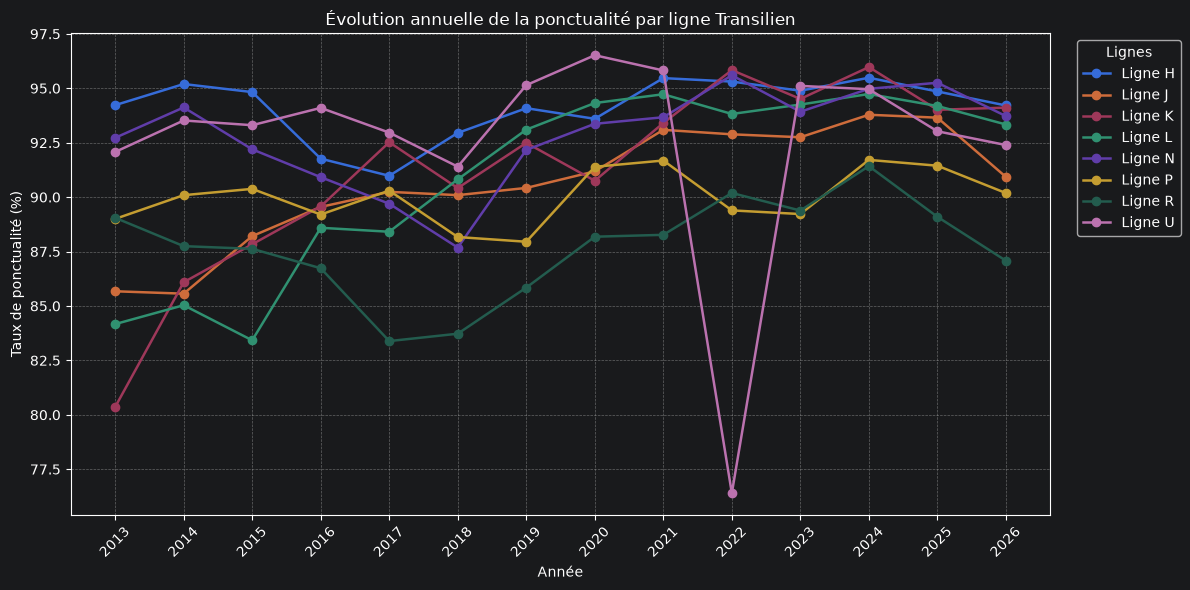

In [8]:
# Graphique 2 : Évolution annuelle par ligne
plt.figure(figsize=(12, 6))

for ligne in evo_annuelle.columns:
  plt.plot(
      evo_annuelle.index,
      evo_annuelle[ligne],
      marker="o",
      linewidth=1.8,
      label=f"Ligne {ligne}",
  )

plt.title("Évolution annuelle de la ponctualité par ligne Transilien")
plt.ylabel("Taux de ponctualité (%)")
plt.xlabel("Année")
plt.xticks(evo_annuelle.index, rotation=45)
plt.grid(True, linestyle="--", alpha=0.5)

# Placer la légende à l'extérieur du graphique pour ne pas masquer les courbes
plt.legend(title="Lignes", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.savefig("graph/2_evolution_annuelle.png", dpi=300)
plt.show()

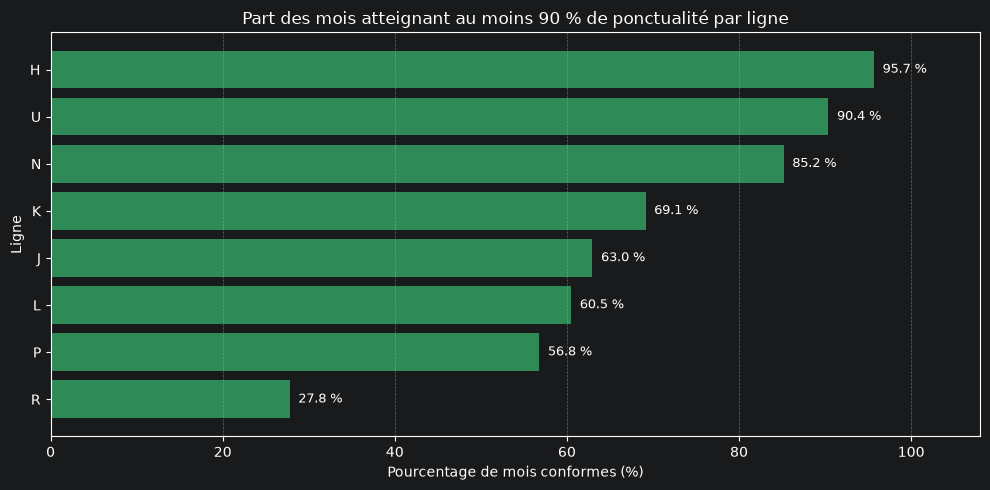

In [9]:
# Graphique 4 : Part des mois atteignant au moins 90 % de ponctualité
conf_trie = taux_conformite.sort_values(ascending=True)

plt.figure(figsize=(10, 5))
bars = plt.barh(conf_trie.index, conf_trie.values, color="#2e8b57")

plt.xlim(0, 108)
plt.title("Part des mois atteignant au moins 90 % de ponctualité par ligne")
plt.xlabel("Pourcentage de mois conformes (%)")
plt.ylabel("Ligne")
plt.grid(axis="x", linestyle="--", alpha=0.5)

# Afficher le pourcentage au bout de chaque barre horizontale
for bar in bars:
  xval = bar.get_width()
  plt.text(
      xval + 1,
      bar.get_y() + bar.get_height() / 2,
      f"{xval:.1f} %",
      va="center",
      fontsize=9,
  )

plt.tight_layout()
plt.savefig("graph/4_conformite_90.png", dpi=300)
plt.show()

In [14]:
# Voir le détail mensuel de 2020 par ligne
covid_2020 = df[df["annee"] == 2020].pivot_table(
    index="mois", columns="ligne", values="taux_de_ponctualite"
)
print(covid_2020.round(2))

ligne      H      J      K      L      N      P      R      U
mois                                                         
2      90.56  86.88  93.16  92.86  92.13  89.12  80.72  95.38
3      95.13  90.74  91.07  94.21  95.28  88.69  85.19  99.41
6      92.92  91.01  92.54  93.31  90.86  92.54  88.99  95.48
7      94.20  92.50  93.24  96.89  94.14  90.45  90.14  96.83
8      90.72  93.51  76.91  95.97  94.97  90.73  92.62  96.76
9      94.27  91.48  93.60  94.43  93.65  93.00  90.62  96.66
10     92.64  89.47  87.64  91.11  93.26  91.47  87.88  95.88
11     95.56  92.98  94.16  96.19  90.56  93.77  90.48  95.83
12     96.39  92.08  94.44  93.94  95.48  92.78  86.99  96.44
